# Machine Learning Methods for N-Dimensional Oscillatory Integrals

## Fresnel Integral in R^N

The simplest higher-dimensional generalisation to the 1D Fresnel integral is $$I = \int\text{d}x_1\text{d}x_2\dots\text{d}x_N\,e^{i\vec x^\text{T} \vec x}\:,$$ where $\text{T}$ denotes transposition and $\vec x = (x_1, \dots, x_N)\in \mathbb R^N$. We may write the integral explicitly in terms of components as
\begin{align}I &= \nonumber \int\text{d}x_1\text{d}x_2\dots\text{d}x_N\,\exp\left(i\sum_{n = 1}^N x_n^2\right)\\
&= \nonumber \int\text{d}x_1\text{d}x_2\dots\text{d}x_N\,\prod_{n=1}^N e^{ix_n^2}\:.
\end{align}
From here, we would like to interpret the integral of the product as a product of integrals. This would require us to invoke the Fubini-Tonelli theorem, which in turn requires that the 1D Fresnel integral be absolutely convergent. We already know that it isn't. The conventional method would have us add a regulator to these integrals so that they do converge absolutely, and then send the regulator to zero at the end. Instead, we will once again invoke Lefschetz thimbles to transform to an equivalent set of integrals which do converge.

Firstly, it is easy to show that the saddle point of the exponent $i\vec x\cdot \vec x$ is $x = 0$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.differentiate import jacobian

In [56]:
def ND_normal_pdf(x, sigma, N):
    return np.exp(-np.sum(x**2, axis=-1)/(2 * sigma**2))/((2*np.pi * sigma**2)**(N/2))

def ND_fresnel_thimble(t):
    return t*(1 + 1j)/np.sqrt(2)

def ND_fresnel_integrand(x):
    return np.exp(1j*np.sum(x**2, axis=-1))


def complex_jacobian(f, x, h=1e-5):
    x = np.asarray(x, dtype=float)
    N = x.size
    J = np.empty((N, N), dtype=complex)

    for j in range(N):
        J[:, j] = (f(x + h) - f(x - h)) / (2*h)

    return J

dimensions = 1
sd = 1
samples = 2000

domain = np.random.randn(samples, dimensions)
jac = np.array([np.linalg.det(complex_jacobian(ND_fresnel_thimble, point)) for point in domain])
weights = jac * ND_fresnel_integrand(
    ND_fresnel_thimble(domain))/ND_normal_pdf(domain, sd, dimensions)
estimate = np.mean(weights)
exact = ((1 + 1j)/np.sqrt(2))**dimensions * np.sqrt(np.pi**dimensions)

print(f"Exact = {exact}. Estimate = {estimate}.")
print(f"Absolute error: {(estimate - exact):.12f}.")
print(f"Relative error: {100*(estimate - exact)/exact:.12f}%.")

Exact = (1.2533141373155001+1.2533141373155001j). Estimate = (1.258125895197488+1.258125895197488j).
Absolute error: 0.004811757882+0.004811757882j.
Relative error: 0.383922732436+0.000000000000j%.


The higher-dimensional analogue of the Fresnel integral is $$I_N = \int_{\mathbb R^N}\text{d}\vec x\,e^{i\vec x\cdot \vec x} = \prod_{n=1}^N\left(\int_{-\infty}^\infty\text{d}x_ne^{ix_n^2}\right)\:.$$ We seek a transformation $\vec x = Az$ which makes the integral Gaussian.

In [ ]:
class ThimbleNetND(nn.Module):
    def __init__(self, n_dim, width=64):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(n_dim, width),
            nn.Tanh(),
            nn.Linear(width, width),
            nn.Tanh(),
            nn.Linear(width, width),
            nn.Tanh(),
            nn.Linear(width, n_dim)
        )

    def forward(self, t):
        theta = self.net(t)
        return t * torch.exp(1j * theta)

Epoch    0 | total loss = 1.8330e+00 | phase loss = 1.7938e+00 | descent loss = 3.9261e-02
Epoch  200 | total loss = 6.6866e-03 | phase loss = 6.6866e-03 | descent loss = 0.0000e+00
Epoch  400 | total loss = 1.1216e-03 | phase loss = 1.1216e-03 | descent loss = 0.0000e+00
Epoch  600 | total loss = 5.3152e-04 | phase loss = 5.3152e-04 | descent loss = 0.0000e+00
Epoch  800 | total loss = 2.2745e-04 | phase loss = 2.2745e-04 | descent loss = 0.0000e+00
Epoch 1000 | total loss = 2.0125e-04 | phase loss = 2.0125e-04 | descent loss = 0.0000e+00
Epoch 1200 | total loss = 9.1879e-05 | phase loss = 9.1879e-05 | descent loss = 0.0000e+00
Epoch 1400 | total loss = 7.5977e-05 | phase loss = 7.5977e-05 | descent loss = 0.0000e+00
Epoch 1600 | total loss = 6.1130e-05 | phase loss = 6.1130e-05 | descent loss = 0.0000e+00
Epoch 1800 | total loss = 5.7902e-05 | phase loss = 5.7902e-05 | descent loss = 0.0000e+00
Epoch 2000 | total loss = 4.5782e-05 | phase loss = 4.5782e-05 | descent loss = 0.0000e+00

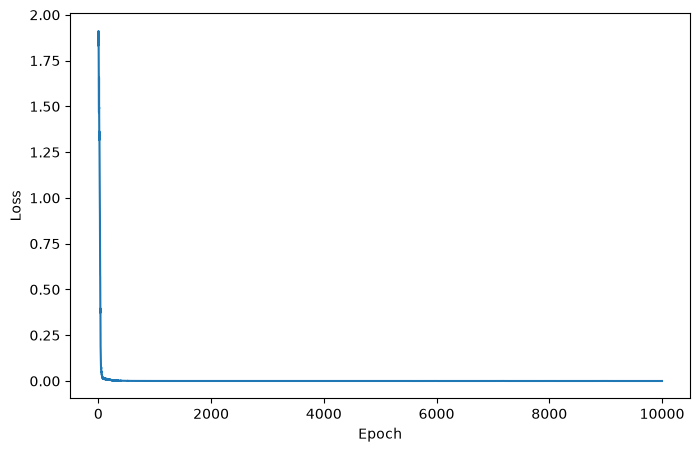

In [ ]:
def contour_map(t, model):
    x = model(t)

    xdot_real = torch.autograd.grad(
        outputs=x.real.sum(), inputs=t, create_graph=True)[0]
    xdot_imag = torch.autograd.grad(
        outputs=x.imag.sum(), inputs=t, create_graph=True)[0]

    xdot = torch.complex(xdot_real, xdot_imag)

    return x, xdot

dimensions = 10
model = ThimbleNetND(dimensions)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

batch_size = 1000
epochs = 10000

loss_hist = []

for epoch in range(epochs):
    optimizer.zero_grad()
    t = torch.randn(batch_size, dimensions, requires_grad=True)

    x = model(t)

    action = x**2
    phase = action.real
    phase_loss = torch.var(phase)

    real_exponent = -torch.imag(action)
    descent_loss = torch.mean(torch.relu(real_exponent)**2)

    loss = phase_loss + descent_loss

    loss.backward()
    optimizer.step()

    loss_hist.append(loss.item())

    if epoch % 200 == 0:
        print(
            f"Epoch {epoch:4d} | total loss = {loss.item():.4e} | phase loss = {phase_loss.item():.4e} | descent loss = {descent_loss.item():.4e}")

fig, ax = plt.subplots(figsize=(8, 5))

plt.xlabel("Epoch")
plt.ylabel("Loss")
ax.plot(loss_hist)
plt.show()